## Parte 1: Esploriamo il dataset

In [50]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import pretty_midi

DATA_DIR = Path("../.venv/data/xmidi/XMIDI_Dataset")
midi_files = list(DATA_DIR.rglob("*.midi"))

print(f"Number of MIDI files : {len(midi_files)}")

Number of MIDI files : 108023


### Iniziamo dando un'occhiata ai file:

In [51]:
midi_files[:20]

[PosixPath('../.venv/data/xmidi/XMIDI_Dataset/XMIDI_warm_jazz_8U8Q3FFZ.midi'),
 PosixPath('../.venv/data/xmidi/XMIDI_Dataset/XMIDI_sad_classical_XNP0EPH2.midi'),
 PosixPath('../.venv/data/xmidi/XMIDI_Dataset/XMIDI_exciting_pop_TPMN9L05.midi'),
 PosixPath('../.venv/data/xmidi/XMIDI_Dataset/XMIDI_funny_country_JVZIL3M5.midi'),
 PosixPath('../.venv/data/xmidi/XMIDI_Dataset/XMIDI_happy_pop_SN74XHLX.midi'),
 PosixPath('../.venv/data/xmidi/XMIDI_Dataset/XMIDI_happy_pop_RCGU9KRC.midi'),
 PosixPath('../.venv/data/xmidi/XMIDI_Dataset/XMIDI_happy_classical_59GFWMKI.midi'),
 PosixPath('../.venv/data/xmidi/XMIDI_Dataset/XMIDI_warm_pop_FFY8JYNX.midi'),
 PosixPath('../.venv/data/xmidi/XMIDI_Dataset/XMIDI_exciting_country_Y0W046K3.midi'),
 PosixPath('../.venv/data/xmidi/XMIDI_Dataset/XMIDI_exciting_country_UG3D2N0O.midi'),
 PosixPath('../.venv/data/xmidi/XMIDI_Dataset/XMIDI_happy_country_EG0I0K45.midi'),
 PosixPath('../.venv/data/xmidi/XMIDI_Dataset/XMIDI_happy_rock_532SC1WV.midi'),
 PosixPath('../.v

### Costruiamo poi il dataframe dividendo le categorie dal path:

In [52]:
records = []

for path in midi_files:
    parts = path.stem.split("_")

    records.append({
        "file": path,
        "emotion": parts[1],
        "genre": parts[2],
        "id": parts[3]
    })
print(records[1])
metadata = pd.DataFrame(records)


{'file': PosixPath('../.venv/data/xmidi/XMIDI_Dataset/XMIDI_sad_classical_XNP0EPH2.midi'), 'emotion': 'sad', 'genre': 'classical', 'id': 'XNP0EPH2'}


In [53]:
metadata.head()

,file,emotion,genre,id
0,../.venv/data/xmidi/XMIDI_Dataset/XMIDI_warm_j...,warm,jazz,8U8Q3FFZ
1,../.venv/data/xmidi/XMIDI_Dataset/XMIDI_sad_cl...,sad,classical,XNP0EPH2
2,../.venv/data/xmidi/XMIDI_Dataset/XMIDI_exciti...,exciting,pop,TPMN9L05
3,../.venv/data/xmidi/XMIDI_Dataset/XMIDI_funny_...,funny,country,JVZIL3M5
4,../.venv/data/xmidi/XMIDI_Dataset/XMIDI_happy_...,happy,pop,SN74XHLX


### Adesso guardiamo come sono distribuite le categorie:
#### 1. Prima le emozioni

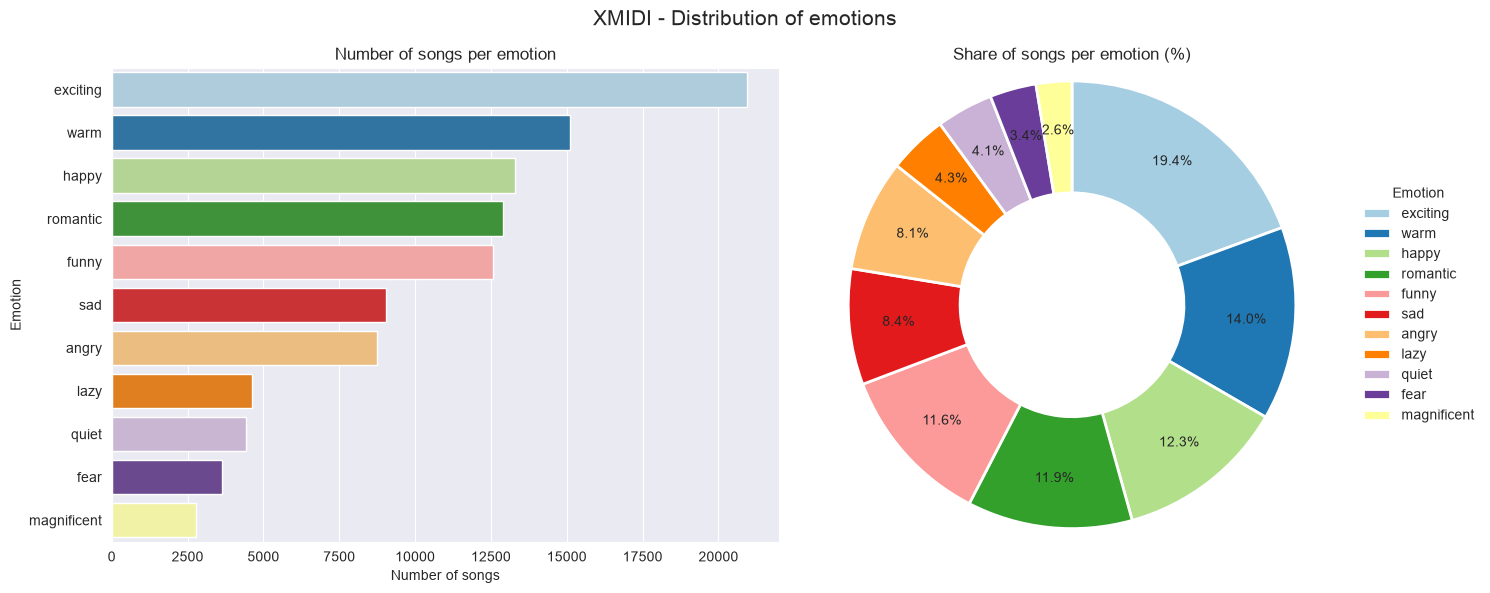

In [54]:
emotion_counts = metadata["emotion"].value_counts()
emotion_pct = metadata["emotion"].value_counts(normalize=True) * 100
order = emotion_counts.index

colors = sns.color_palette("Paired", n_colors=len(order))
palette = dict(zip(order, colors))   #stesso colore per ogni emozione

fig, axes = plt.subplots(1, 2, figsize=(15, 6), facecolor="white",
                         gridspec_kw={"width_ratios": [1.2, 1]})

#barre
sns.countplot(
    data=metadata,
    y="emotion",
    order=order,
    hue="emotion",
    palette=palette,
    legend=False,
    ax=axes[0],
)
axes[0].set_xlabel("Number of songs")
axes[0].set_ylabel("Emotion")
axes[0].set_title("Number of songs per emotion")

#torta
wedges, texts, autotexts = axes[1].pie(
    emotion_pct[order],
    labels=None,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    colors=colors,
    pctdistance=0.78,
    wedgeprops={"edgecolor": "white", "linewidth": 2, "width": 0.5},
    textprops={"fontsize": 10},
)
axes[1].legend(
    wedges,
    order,
    title="Emotion",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    frameon=False,
)
axes[1].set_title("Share of songs per emotion (%)")
axes[1].axis("equal")

fig.suptitle("XMIDI - Distribution of emotions", fontsize=15)
plt.tight_layout()
plt.show()

In [55]:
metadata["emotion"].value_counts()

emotion
exciting       20948
warm           15090
happy          13291
romantic       12886
funny          12565
sad             9038
angry           8739
lazy            4622
quiet           4431
fear            3621
magnificent     2792
Name: count, dtype: int64

 Si può notare la presenza di una sottorappresentazione riguardante alcune emotion che dovrà essere considerata in fase di train

#### 2. Poi i generi

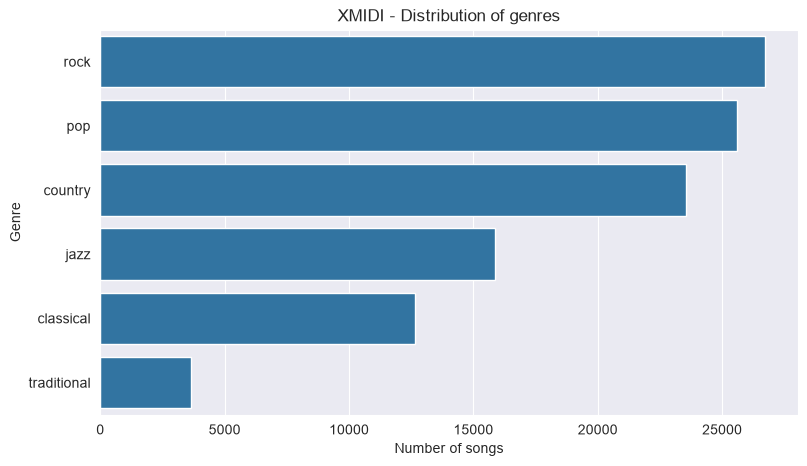

In [56]:
metadata["genre"].value_counts()
plt.figure(figsize=(9, 5))

sns.countplot(
    data=metadata,
    y="genre",
    order=metadata["genre"].value_counts().index
)

plt.xlabel("Number of songs")
plt.ylabel("Genre")
plt.title("XMIDI - Distribution of genres")

plt.show()


In [57]:
metadata["genre"].value_counts()

genre
rock           26708
pop            25582
country        23551
jazz           15862
classical      12660
traditional     3660
Name: count, dtype: int64

Anche per quanto riguarda la distribuzione dei generi si può notare che la classe traditional è sottorappresentata.

#### 3. Infine guardiamo se c'è una relazione tra emozione e genere

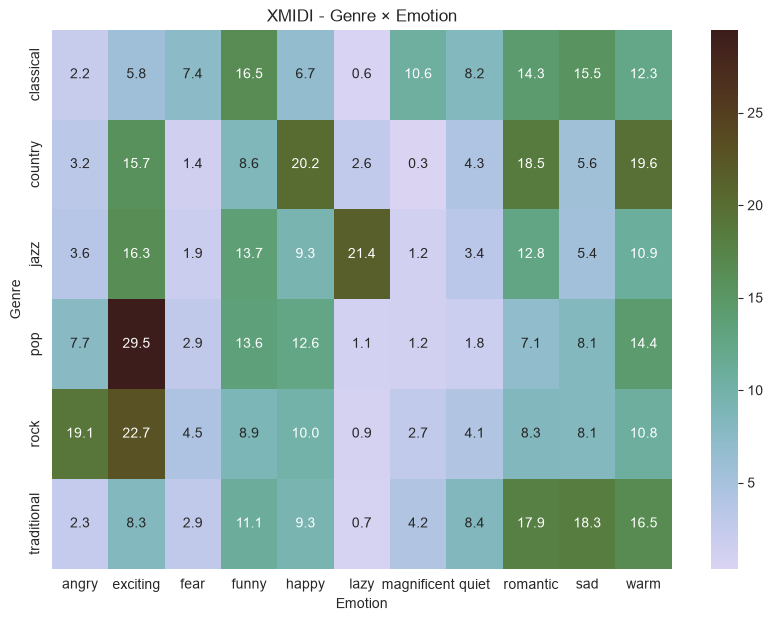

In [58]:
genre_emotion = pd.crosstab(
    metadata["genre"],
    metadata["emotion"],
    normalize="index"
) * 100

plt.figure(figsize=(10, 7))

sns.heatmap(
    genre_emotion,
    annot=True,
    fmt=".1f",
    cmap=sns.cubehelix_palette(start=.5, rot=1, as_cmap=True)
)

plt.xlabel("Emotion")
plt.ylabel("Genre")
plt.title("XMIDI - Genre × Emotion")

plt.show()

Si può notare un'associazione tra le due variabili, con alcune emozioni, come la rabbia, l'eccitazione o la pigrizia maggiormente rappresentate in determinati generi musicali. 

Le combinazioni di genere ed emozione non sono quindi distribuite uniformemente nel dataset.

---
*Passiamo adesso ad un'analisi più dettagliata del contenuto dei file midi*


### Estraiamo alcune caratteristiche musicali:

In [59]:
midi_stats = []
for path in tqdm(midi_files, desc="Analyzing MIDI files"):

        midi = pretty_midi.PrettyMIDI(str(path))

        #Durata
        duration = midi.get_end_time()

        #Note totali
        n_notes = sum(len(instrument.notes)
                      for instrument in midi.instruments)

        #numero parti strumentali
        n_instruments = len(midi.instruments)
        
        #numero parti percussive
        n_drum_tracks = sum(instrument.is_drum
                            for instrument in midi.instruments)

        midi_stats.append({
            "file": path,
            "duration": duration,
            "n_notes": n_notes,
            "n_instruments": n_instruments,
            "n_drum_tracks": n_drum_tracks,
            
        })   

Analyzing MIDI files:   0%|          | 0/108023 [00:00<?, ?it/s]

In [60]:
#converto in un dataframe panadas
midi_stats = pd.DataFrame(midi_stats)

print("Successfully parsed:", len(midi_stats))

Successfully parsed: 108023


In [61]:
# Cartella risultati
output_dir = Path("../risultati")
output_dir.mkdir(parents=True, exist_ok=True)

# Salvataggio CSV
midi_stats.to_csv(
    output_dir / "xmidi_midi_stats.csv",
    index=False
)

In [62]:
midi_stats = pd.read_csv(output_dir / "xmidi_midi_stats.csv")
metadata["file"] = metadata["file"].astype(str)
midi_stats["file"] = midi_stats["file"].astype(str)

eda_df = metadata.merge(
    midi_stats,
    on="file",
    how="left"
)
eda_df.head()

,file,emotion,genre,id,duration,n_notes,n_instruments,n_drum_tracks
0,../.venv/data/xmidi/XMIDI_Dataset/XMIDI_warm_j...,warm,jazz,8U8Q3FFZ,272.647232,4395,7,1
1,../.venv/data/xmidi/XMIDI_Dataset/XMIDI_sad_cl...,sad,classical,XNP0EPH2,68.382396,312,2,0
2,../.venv/data/xmidi/XMIDI_Dataset/XMIDI_exciti...,exciting,pop,TPMN9L05,153.466484,4207,5,1
3,../.venv/data/xmidi/XMIDI_Dataset/XMIDI_funny_...,funny,country,JVZIL3M5,215.987532,4898,5,1
4,../.venv/data/xmidi/XMIDI_Dataset/XMIDI_happy_...,happy,pop,SN74XHLX,163.424473,3722,3,1


### Ed analizziamole:

### 1. Durata

In [63]:
eda_df["duration"].describe(
    percentiles=[.01, .25, .5, .75, .95, .99]
)

count    108023.000000
mean        176.258219
std          60.986619
min           2.450493
1%           60.504240
25%         131.347368
50%         175.714397
75%         221.344678
95%         275.924545
99%         294.453968
max        1186.848000
Name: duration, dtype: float64

In [64]:
print("Brani senza note:",(eda_df["n_notes"] == 0).sum())
print( "Brani con durata nulla:",(eda_df["duration"] == 0).sum())

Brani senza note: 0
Brani con durata nulla: 0


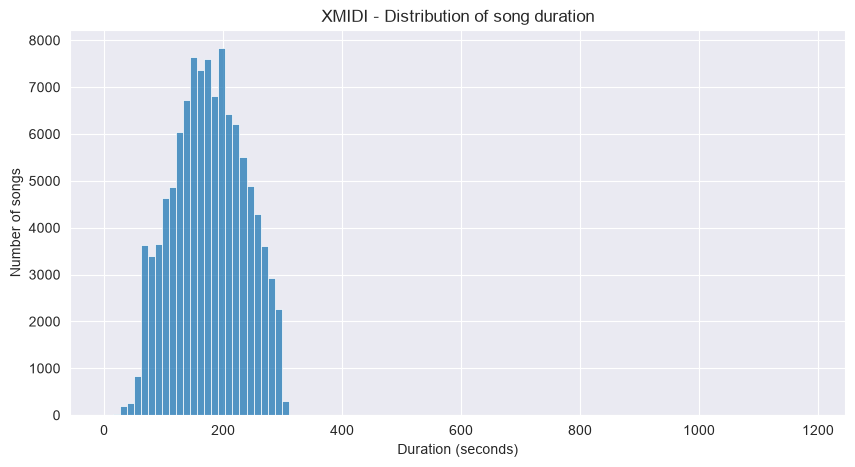

In [65]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=eda_df,
    x="duration",
    bins=100
)

plt.xlabel("Duration (seconds)")
plt.ylabel("Number of songs")
plt.title("XMIDI - Distribution of song duration")

plt.show()

Come si può notare dall'istogramma la maggior parte delle canzoni ha una durata che si aggira intorno ai 150-250 secondi, con la presenza però di alcuni outlier.

### 2. Numero di note

In [66]:
eda_df["n_notes"].describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99]
)

count    108023.000000
mean       3519.614971
std        2206.951461
min           8.000000
1%          312.220000
5%          683.000000
25%        1884.000000
50%        3165.000000
75%        4706.000000
95%        7611.000000
99%       10301.000000
max       25364.000000
Name: n_notes, dtype: float64

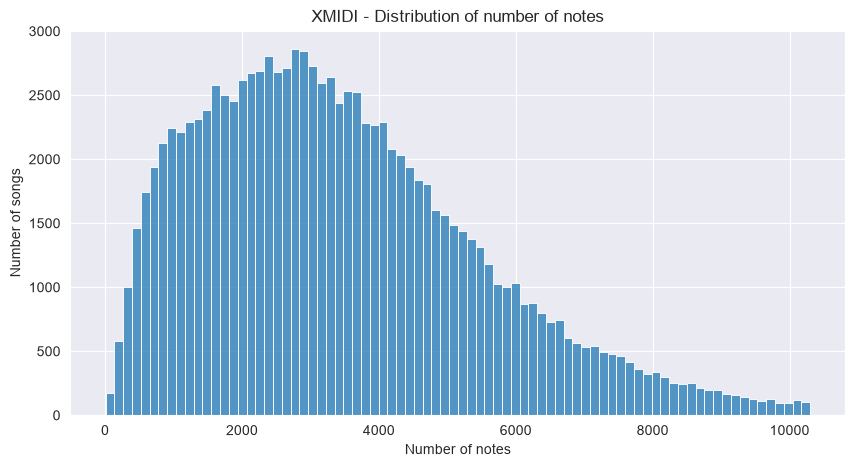

In [67]:
#per rendere il grafico più leggibile mostro solo  
# brani con un numero di note <= al 0.99 percentile
q99_notes = eda_df["n_notes"].quantile(0.99)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=eda_df[eda_df["n_notes"] <= q99_notes],
    x="n_notes",
    bins=80
)

plt.xlabel("Number of notes")
plt.ylabel("Number of songs")
plt.title("XMIDI - Distribution of number of notes")

plt.show()

Qui invece la distribuzione del numero di note dei brani è più ampia e presenta una coda spostata verso destra. Questo indica che un numero significativo di brani ha un numero di note superiore rispetto al resto.


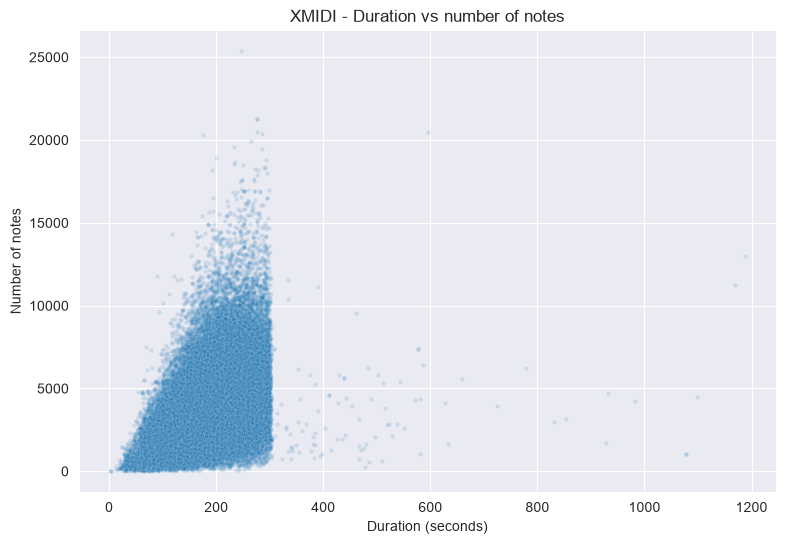

In [68]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=eda_df,
    x="duration",
    y="n_notes",
    alpha=0.15,
    s=10
)

plt.xlabel("Duration (seconds)")
plt.ylabel("Number of notes")
plt.title("XMIDI - Duration vs number of notes")

plt.show()

Questo grafico serve ad evidenziare la relazione tra la durata dei brani e il numero delle note. Nonostante la dispersione elevata e la presenza di valori estremi si può notare una tendenza positiva tra i due, quindi generalmente possiamo affermare che i brani più lunghi contengono più note

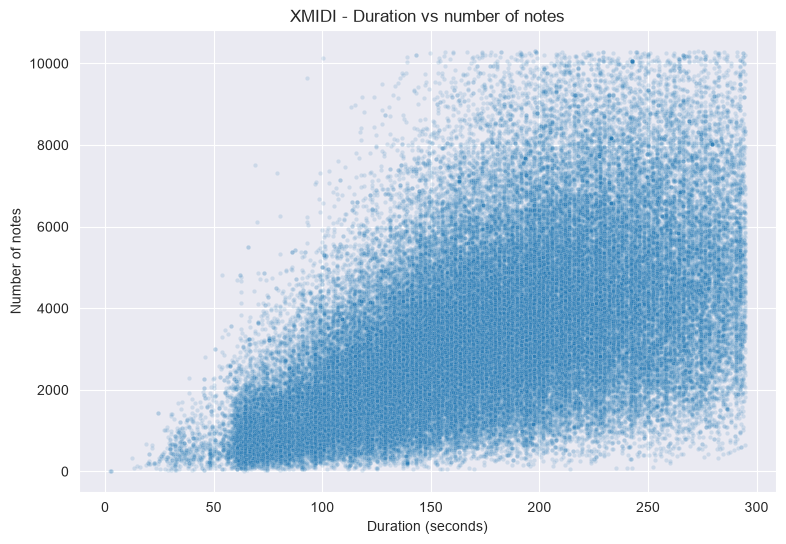

In [69]:
#non so se mi conviene farlo con il 99 percentile
plot_df = eda_df[
    (eda_df["duration"] <= eda_df["duration"].quantile(.99)) &
    (eda_df["n_notes"] <= eda_df["n_notes"].quantile(.99))
]

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=plot_df,
    x="duration",
    y="n_notes",
    alpha=0.15,
    s=10
)

plt.xlabel("Duration (seconds)")
plt.ylabel("Number of notes")
plt.title("XMIDI - Duration vs number of notes")

plt.show()

Escludendo i valori che superano il 99° percentile questa relazione positiva risulta più evidente. Tuttavia anche in questo grafico si può notare una dispersione verticale che è dovuta al fatto che brani di durata simile possono avere un numero di note molto differente.

### 3. Numero di strumenti

In [70]:
eda_df["n_instruments"].describe()

count    108023.000000
mean          4.263953
std           1.461841
min           2.000000
25%           3.000000
50%           4.000000
75%           5.000000
max          17.000000
Name: n_instruments, dtype: float64

Questo ci mostra che c'è almeno un brano in cui sono presenti tutti gli strumenti presenti all'interno del dataset ma in media in un brano vengono utilizzati 4 strumenti diversi

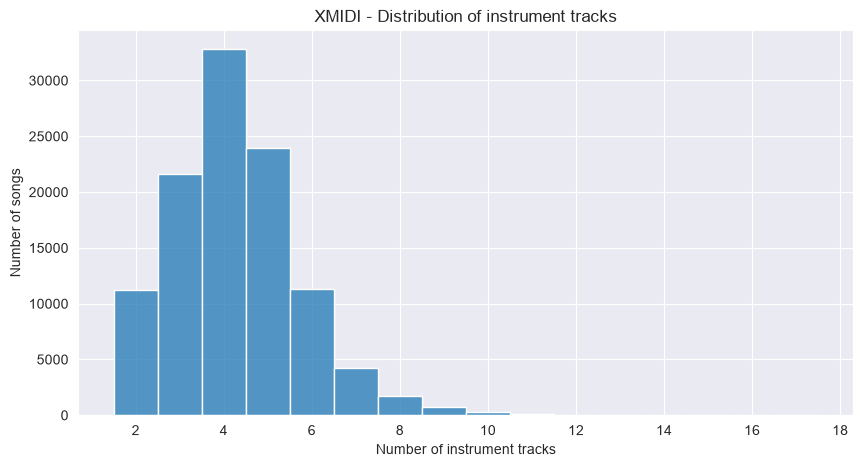

In [71]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=eda_df,
    x="n_instruments",
    discrete=True
)

plt.xlabel("Number of instrument tracks")
plt.ylabel("Number of songs")
plt.title("XMIDI - Distribution of instrument tracks")

plt.show()

### 4. Tracce percussive

In [72]:
eda_df["n_drum_tracks"].value_counts().sort_index()

n_drum_tracks
0    14476
1    93547
Name: count, dtype: int64

Questo evidenzia che la grande maggioranza dei brani presenta almeno una traccia percussiva.

In [73]:
eda_df["has_drums"] = eda_df["n_drum_tracks"] > 0

pd.crosstab(
    eda_df["genre"],
    eda_df["has_drums"],
    normalize="index"
).round(3)


has_drums,False,True
genre,,
classical,0.628,0.372
country,0.019,0.981
jazz,0.043,0.957
pop,0.047,0.953
rock,0.088,0.912
traditional,0.504,0.496


Si può notare che 

### 5. Boxplots oer genere ed emozione

##### In tutti questi grafici è stato applicato il filtro al 99° percentile per rendere i grafici più leggibili

#### 5.1 Durata dei brani per genere

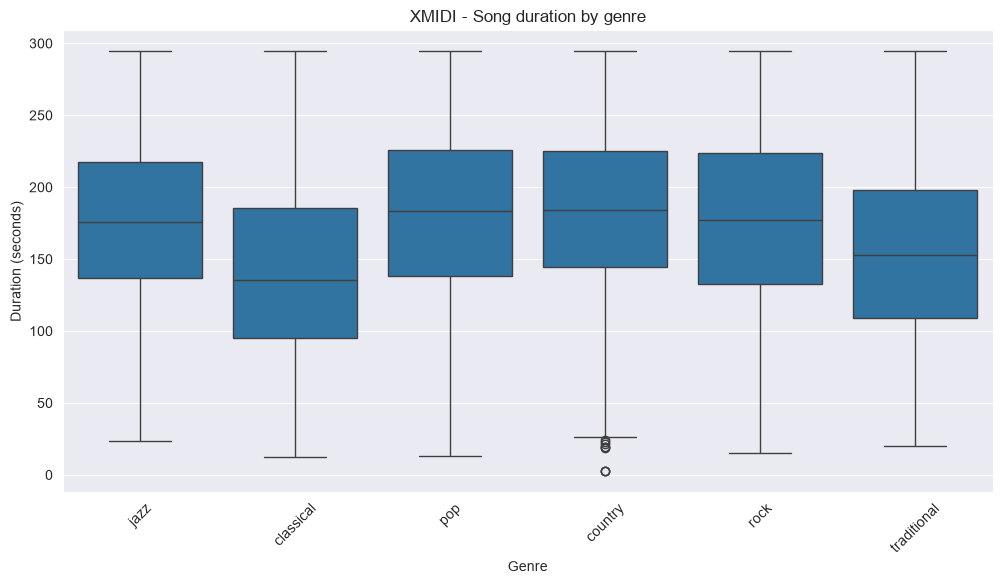

In [74]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=eda_df[
        eda_df["duration"]
        <= eda_df["duration"].quantile(.99)
    ],
    x="genre",
    y="duration"
)

plt.xticks(rotation=45)
plt.xlabel("Genre")
plt.ylabel("Duration (seconds)")
plt.title("XMIDI - Song duration by genre")

plt.show()

Si può notare che la durata presenta delle leggere differenze a seconda del genere musicale. In particolare si vede che i brani Classici hanno una durata mediana inferiore rispetto agli altri, ma le distribuzioni in generale risultano sovrapposte. 

#### 5.2 Durata dei brani per emozione

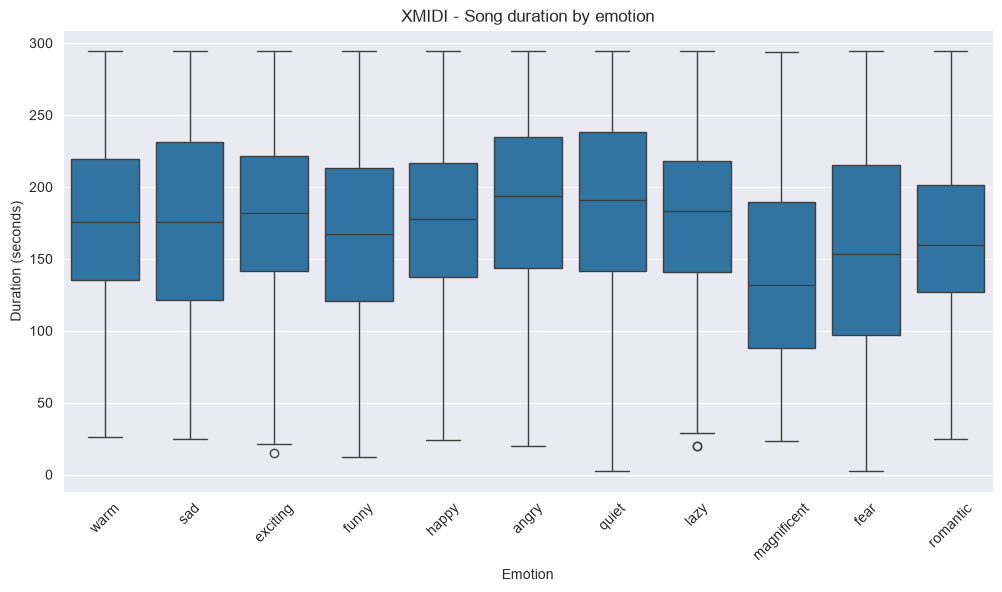

In [75]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=eda_df[
        eda_df["duration"]
        <= eda_df["duration"].quantile(.99)
    ],
    x="emotion",
    y="duration"
)

plt.xticks(rotation=45)
plt.xlabel("Emotion")
plt.ylabel("Duration (seconds)")
plt.title("XMIDI - Song duration by emotion")

plt.show()

Per quanto riguarda la durata dei brani per emozione si possono notare delle leggere differenze tra le varie emozioni, tuttavia le distribuzioni risultano ampiamente sovrapposte, il che suggerisce che la durata da sola è una caratteristica poco discriminativa per distinguere le emozioni

#### 5.3 Densità delle note per genere

In [76]:
eda_df["note_density"] = (
    eda_df["n_notes"] /
    eda_df["duration"].replace(0, np.nan)
)

##### N.B. CAlcolando la note density in questo modo si considerano tutte le note di tutte le tracce strumentali del brano. Quindi se un brano ha molti strumenti che suonano contemporaneamente potrebbe avere una densità elevata anche non essendo molto veloce

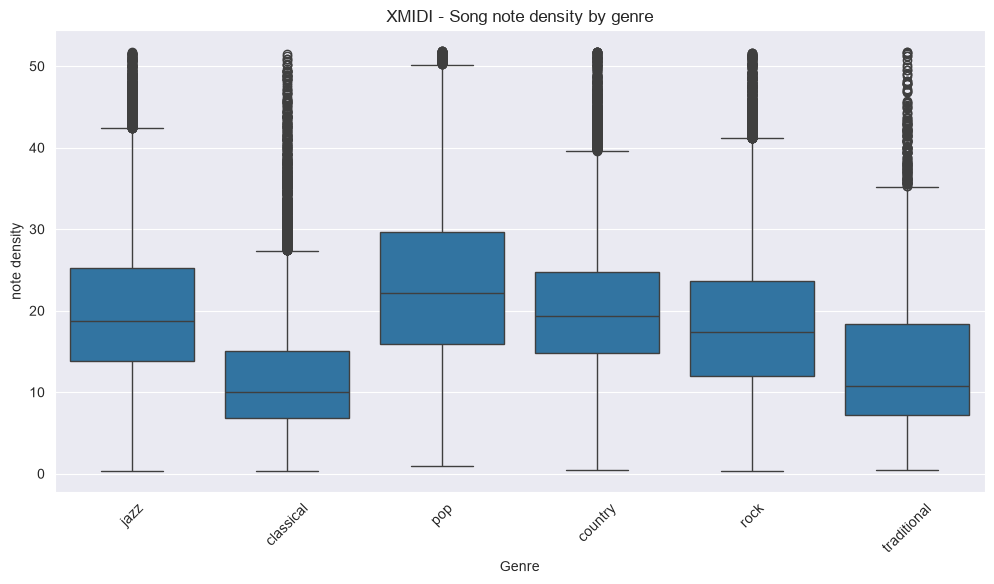

In [77]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=eda_df[
        eda_df["note_density"]
        <= eda_df["note_density"].quantile(.99)
    ],
    x="genre",
    y="note_density"
)

plt.xticks(rotation=45)
plt.xlabel("Genre")
plt.ylabel("note density")
plt.title("XMIDI - Song note density by genre")

plt.show()

Per quanto riguarda la densità delle note tra i generi si può notare che anche in questo caso i brani Classical e Traditional mostrano valori più bassi rispetto agli altri generi. 
Inoltre è importante notare la presenza di numerosi valori estremi 

#### 5.4 Densità delle note per emozione

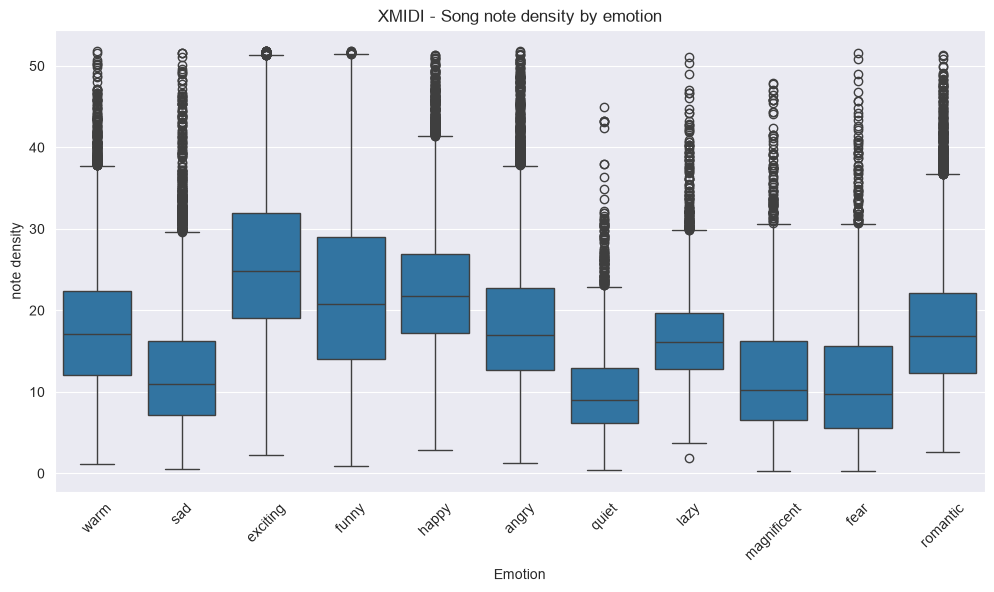

In [79]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=eda_df[
        eda_df["note_density"]
        <= eda_df["note_density"].quantile(.99)
    ],
    x="emotion",
    y="note_density"
)

plt.xticks(rotation=45)
plt.xlabel("Emotion")
plt.ylabel("note density")
plt.title("XMIDI - Song note density by emotion")

plt.show()

Anche in questo caso la densità delle note evidenzia delle differenze più marcate rispetto alla durata. 
In particolare emozioni come excited e happy presentano un valore mediano più elevato, mentre quiet e fear mostrano mediane più basse.
Anche qui si nota la oresenza di numerosi valori estremi.